# **Email Spam Detection**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

plt.style.use('ggplot')

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv('D:\\Projects\\ML\\Email-Spam-Detection\data\\email.csv')

# EDA

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5573 entries, 0 to 5572
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Category  5573 non-null   str  
 1   Message   5573 non-null   str  
dtypes: str(2)
memory usage: 542.3 KB


In [4]:
df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
df.tail()

,Category,Message
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...
5571,ham,Rofl. Its true to its name
5572,"{""mode"":""full""",isActive:false}


In [6]:
df['Category'].value_counts()

Category
ham               4825
spam               747
{"mode":"full"       1
Name: count, dtype: int64

In [7]:
df = df.iloc[:-1]

In [8]:
df.tail()

,Category,Message
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...
5571,ham,Rofl. Its true to its name


In [9]:
print(f'Row Numbers: {df.shape[0]}')
print(f'Columns Numbers: {df.shape[1]}')

Row Numbers: 5572
Columns Numbers: 2


In [10]:
df.dtypes

Category    str
Message     str
dtype: object

In [11]:
df.isnull().sum()

Category    0
Message     0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(415)

In [13]:
df.drop_duplicates(inplace=True)

In [14]:
df.Category.value_counts()

Category
ham     4516
spam     641
Name: count, dtype: int64

In [15]:
df["Category"].value_counts(normalize=True) * 100

Category
ham     87.570293
spam    12.429707
Name: proportion, dtype: float64

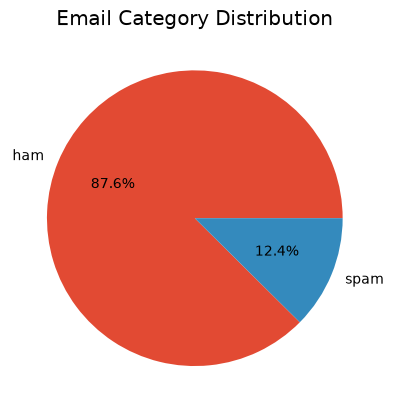

In [16]:
df["Category"].value_counts().plot(
    kind="pie",
    autopct='%1.1f%%'
)
plt.title("Email Category Distribution")
plt.show()

# Message Length Analysis

In [17]:
df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [18]:
df["Message_Length"] = df["Message"].apply(len)
df.head(7)

,Category,Message,Message_Length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61
5,spam,FreeMsg Hey there darling it's been 3 week's n...,147
6,ham,Even my brother is not like to speak with me. ...,77


In [19]:
df["Message"][2]

"Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's"

In [20]:
df["Message_Length"].describe()

count    5157.000000
mean       79.103936
std        58.382922
min         2.000000
25%        36.000000
50%        61.000000
75%       118.000000
max       910.000000
Name: Message_Length, dtype: float64

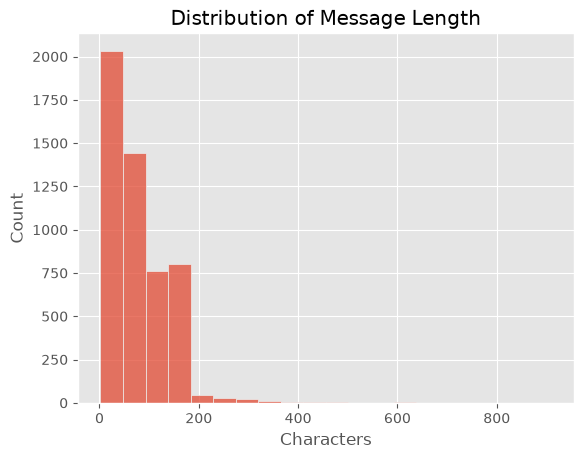

In [21]:
sns.histplot(
    df["Message_Length"], 
    bins=20
)
plt.title("Distribution of Message Length")
plt.xlabel("Characters")
plt.show()

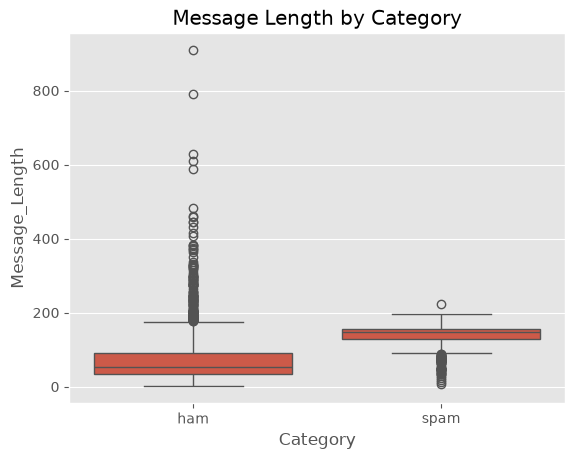

In [22]:
sns.boxplot(
    data=df,
    x='Category',
    y='Message_Length'
)
plt.title("Message Length by Category")
plt.show()

In [23]:
df.groupby("Category")["Message_Length"].mean()

Category
ham      70.869353
spam    137.118565
Name: Message_Length, dtype: float64

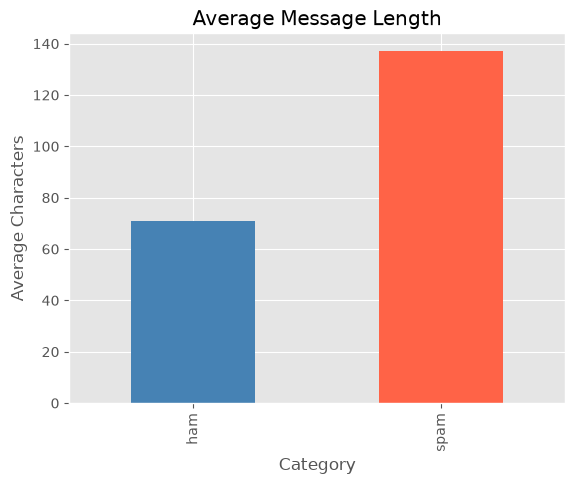

In [24]:
df.groupby("Category")["Message_Length"].mean().plot(
    kind="bar",
    color=["steelblue", "tomato"]
)
plt.ylabel("Average Characters")
plt.title("Average Message Length")
plt.show()

# Word Count and Data Insights

In [25]:
df.sample(10)

,Category,Message,Message_Length
1063,ham,Ok. Not sure what time tho as not sure if can ...,122
1230,ham,Jus ans me lar. U'll noe later.,31
1572,ham,Near kalainar tv office.thenampet,33
3396,ham,Then i buy.,11
65,spam,"As a valued customer, I am pleased to advise y...",152
3643,ham,My house here e sky quite dark liao... If rain...,98
3620,spam,8007 25p 4 Alfie Moon's Children in Need song ...,165
5568,ham,Will ü b going to esplanade fr home?,36
5006,ham,Guess which pub im in? Im as happy as a pig in...,80
1364,ham,"Yetunde, i'm sorry but moji and i seem too bus...",207


In [26]:
df['Word_Count'] = df["Message"].apply(lambda x:len(x.split()))
df.sample(10)

,Category,Message,Message_Length,Word_Count
1612,ham,645,3,1
2098,ham,Are you the cutest girl in the world or what,44,10
2620,spam,<Forwarded from 21870000>Hi - this is your Mai...,173,27
3754,ham,Ya that one is slow as poo,26,7
725,ham,The world is running and i am still.maybe all ...,226,42
3530,spam,Xmas & New Years Eve tickets are now on sale f...,157,32
2189,spam,FREE camera phones with linerental from 4.49/m...,152,24
2581,spam,U are subscribed to the best Mobile Content Se...,133,25
5427,spam,Santa Calling! Would your little ones like a c...,106,19
2267,spam,<Forwarded from 88877>FREE entry into our £250...,121,20


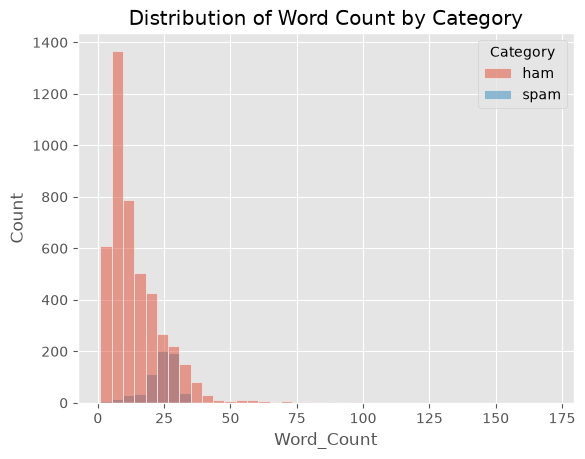

In [27]:
sns.histplot(
    data=df,
    x="Word_Count",
    hue="Category",
    bins=40
)
plt.title("Distribution of Word Count by Category")
plt.show()

In [28]:
df.groupby("Category")["Word_Count"].mean()

Category
ham     14.239814
spam    23.659906
Name: Word_Count, dtype: float64

In [29]:
df.nsmallest(10, "Message_Length")

,Category,Message,Message_Length,Word_Count
1925,ham,Ok,2,1
3376,ham,:),2,1
261,ham,Yup,3,1
1612,ham,645,3,1
2182,ham,Ok.,3,1
287,ham,Ok..,4,1
2602,ham,Okie,4,1
5173,ham,U 2.,4,2
1273,ham,Ok...,5,1
4293,ham,G.W.R,5,1


In [30]:
df.nlargest(10, "Message_Length")

,Category,Message,Message_Length,Word_Count
1085,ham,For me the love should start with attraction.i...,910,171
1863,ham,The last thing i ever wanted to do was hurt yo...,790,162
2434,ham,Indians r poor but India is not a poor country...,629,109
1579,ham,How to Make a girl Happy? It's not at all diff...,611,103
2158,ham,Sad story of a Man - Last week was my b'day. M...,588,125
2380,ham,"Good evening Sir, hope you are having a nice d...",482,98
3017,ham,"&lt;#&gt; is fast approaching. So, Wish u a v...",461,66
1513,ham,"Hey sweet, I was wondering when you had a mome...",458,95
2370,ham,A Boy loved a gal. He propsd bt she didnt mind...,446,96
2408,ham,Solve d Case : A Man Was Found Murdered On &l...,444,71


In [31]:
df[df['Category'] == 'spam'].sample(5)

,Category,Message,Message_Length,Word_Count
4506,spam,Mobile Club: Choose any of the top quality ite...,73,13
3595,spam,Do you want a New Nokia 3510i Colour Phone Del...,157,29
5482,spam,URGENT We are trying to contact you Last weeke...,148,27
2525,spam,FREE entry into our £250 weekly comp just send...,99,18
4725,spam,FREE GAME. Get Rayman Golf 4 FREE from the O2 ...,153,29


In [32]:
df[df['Category'] == 'ham'].sample(5)

,Category,Message,Message_Length,Word_Count
5089,ham,What type of stuff do you sing?,31,7
493,ham,"Sorry,in meeting I'll call later",32,5
2262,ham,Did you show him and wot did he say or could u...,64,17
1648,ham,Evening * v good if somewhat event laden. Will...,130,28
555,ham,I‘ll have a look at the frying pan in case it‘...,127,28


# Data Preprocessing

In [33]:
df['Category'] = df['Category'].map({
    'ham': 0,
    'spam': 1
})

In [34]:
df.sample(5)

,Category,Message,Message_Length,Word_Count
5306,0,Ill be at yours in about 3 mins but look out f...,51,13
654,0,Fine i miss you very much.,26,6
3496,1,Wan2 win a Meet+Greet with Westlife 4 U or a m...,161,30
2645,0,My friends use to call the same.,32,7
3577,0,The sign of maturity is not when we start sayi...,154,27


# Feature Engineering

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [36]:
X = df['Message']
Y = df['Category']
x_train, x_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size= 0.2,
    stratify= Y
)

In [37]:
tf_idf = TfidfVectorizer(
    stop_words='english',
    max_features=5000,
    ngram_range=(1, 2)
)

x_train_tfidf = tf_idf.fit_transform(x_train)
x_test_tfidf = tf_idf.transform(x_test)